# 01 - Exploratory Data Analysis (EDA)
## Notebook 1: Memahami Dataset HAM10000 Sebelum Membangun Model

**Tujuan notebook ini:**
1. Memahami ARTI setiap variabel di dataset HAM10000
2. Mencek masalah data: apakah datanya bersih? seimbang? ada anomali?
3. Membuat visualisasi yang mendukung keputusan preprocessing
4. Merekam temuan yang akan menjadi dasar keputusan di notebook berikutnya

**Aturan yang kita pegang:**
- Setiap grafik HARUS punya penjelasan interpretasi, bukan cuma ditampilkan
- Tidak boleh ada angka yang dikarang. Semua angka di bawah dihitung dari kode
- Tidak boleh dipakai data test untuk keputusan apa pun di notebook ini

**Konteks:** Fase 0 (persiapan) sudah selesai. Dataset terverifikasi:
10.015 gambar, 0 file hilang, 0 file kosong.


In [1]:
# --- Persiapan: import library dan set seed ---
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf

from src import config as C
from src import data_loader

warnings.filterwarnings("ignore")

# Set seed supaya semua hasil di notebook ini bisa direproduksi
np.random.seed(C.SEED)
tf.random.set_seed(C.SEED)

# Style visualisasi yang konsisten
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["figure.autolayout"] = True

print("TensorFlow:", tf.__version__)
print("Seed:", C.SEED)
print("Repo root:", REPO_ROOT)


TensorFlow: 2.21.0
Seed: 42
Repo root: M:\GrenPlums Roses\Program32bit\Forestrypansy\ML2026_Kelas_3_Kelompok_1_LesiKulit


## Bagian 1: Apa Itu Dataset HAM10000?

**HAM10000** (*Human Against Machine with 10,000 images*) adalah dataset
dermatologi yang dibuat oleh tim di Universitas Graz, Austria, DAN
Queensland, Australia, diterbitkan pada tahun 2018 (Tschandl dkk.,
*Scientific Data*).

Dataset ini berisi **foto lesi kulit yang diambil dengan dermatoskop**,
yaitu alat mikroskop khusus yang memungkinkan kita melihat pola permukaan kulit
yang tidak terlihat dengan mata telanjang.

**Kenapa dataset ini penting untuk skrining kanker?**
Melanoma adalah jenis kanker kulit yang **berbahaya** karena stadium awal
biasanya tidak sakit, jadi orang sering menunda periksa. Deteksi dini
meningkatkan peluang kesembuhannya secara signifikan. Karena itu,
alat bantu skrining otomatis punya nilai praktis yang nyata.

**Sumber dataset:**
- Kaggle: "Skin Cancer MNIST: HAM10000"
- Harvard Dataverse: "HAM10000" oleh Tschandl dkk. (doi: 10.7910/DVN/DBX6T5)

**Lisensi: CC BY-NC 4.0** (komersial non-komersial).
Hanya boleh dipakai untuk keperluan **akademik/non-komersial**.
Ini WAJIB dicantumkan di laporan dan di aplikasi.


In [2]:
# --- Definisi arti setiap variabel ---
# Kita dokumentasikan arti setiap kolom DI SINI, karena ini bagian dari
# laporan yang sering ditanyakan saat tanya jawab.

VARIABLE_DOC = {
    "lesion_id": (
        "ID unik untuk satu LESI (bukan satu foto). Satu lesi bisa punya "
        "beberapa foto (diambil dari sudut berbeda). PENTING: split data "
        "harus dilakukan per lesion_id untuk mencegah data leakage."
    ),
    "image_id": (
        "ID unik untuk satu FILE GAMBAR. Nama filenya adalah "
        "image_id + '.jpg'. Tiap baris metadata = satu file gambar."
    ),
    "dx": (
        "Diagnosis dermatologis (kode). 7 kelas: akiec, bcc, bkl, df, mel, "
        "nv, vasc. Ini adalah TARGET (label) yang akan diprediksi model."
    ),
    "dx_type": (
        "Wie jenis penentuan diagnosis: 'histo' = dari biopsi histopatologi "
        "(pemeriksaan potongan jaringan - GOLD STANDARD), 'follow_up' = "
        "diagnosis dari pemeriksaan lanjutan (biasanya setelah beberapa bulan "
        "lesi berubah), 'confocal' = lewat mikroskop confocal, 'consensus' = "
        "keputusan konsensus beberapa dokter. PENTING: hanya kelas dengan "
        "dx_type='histo' yang diagnosisnya paling pasti."
    ),
    "age": (
        "Usia pasien dalam tahun. Ada 57 nilai kosong (missing)."
    ),
    "sex": (
        "Jenis kelamin pasien: male, female, atau unknown."
    ),
    "localization": (
        "Lokasi lesi di tubuh: axial, torso, extremities, dll. Berguna "
        "untuk EDA tapi TIDAK dipakai sebagai feature model (hanya gambar "
        "yang diproses model, sesuai desain project)."
    ),
}

print("=" * 78)
print("DOKUMENTASI VARIABEL DATASET HAM10000")
print("=" * 78)
for col, desc in VARIABLE_DOC.items():
    print(f"\n{col.upper()}")
    print(f"  {desc}")


DOKUMENTASI VARIABEL DATASET HAM10000

LESION_ID
  ID unik untuk satu LESI (bukan satu foto). Satu lesi bisa punya beberapa foto (diambil dari sudut berbeda). PENTING: split data harus dilakukan per lesion_id untuk mencegah data leakage.

IMAGE_ID
  ID unik untuk satu FILE GAMBAR. Nama filenya adalah image_id + '.jpg'. Tiap baris metadata = satu file gambar.

DX
  Diagnosis dermatologis (kode). 7 kelas: akiec, bcc, bkl, df, mel, nv, vasc. Ini adalah TARGET (label) yang akan diprediksi model.

DX_TYPE
  Wie jenis penentuan diagnosis: 'histo' = dari biopsi histopatologi (pemeriksaan potongan jaringan - GOLD STANDARD), 'follow_up' = diagnosis dari pemeriksaan lanjutan (biasanya setelah beberapa bulan lesi berubah), 'confocal' = lewat mikroskop confocal, 'consensus' = keputusan konsensus beberapa dokter. PENTING: hanya kelas dengan dx_type='histo' yang diagnosisnya paling pasti.

AGE
  Usia pasien dalam tahun. Ada 57 nilai kosong (missing).

SEX
  Jenis kelamin pasien: male, female, atau u

## Bagian 2: Memuat dan Memverifikasi Data

Kita TIDAK langsung percaya dataset-nya. Modul `data_loader` memverifikasi
bahwa setiap `image_id` di metadata benar-benar punya file gambar di disk.
Kalau ada yang tidak cocok, semua indeks label akan bergeser dan seluruh
analisis jadi tidak dipercaya.


In [3]:
df = data_loader.load_metadata()
report = data_loader.verify_dataset_integrity(df, verbose=True)

# Tampilkan 5 baris pertama supaya jelas bentuk datanya
print("\n--- 5 baris pertama ---")
display(df.head())

print("\n--- Tipe data setiap kolom ---")
display(df.dtypes.to_frame("tipe_data"))


=== RINGKASAN INTEGRITAS DATASET ===
  n_rows_metadata: 10015
  n_unique_lesion_id: 7470
  n_unique_image_id: 10015
  n_missing_image_file: 0
  n_zero_byte_image: 0
  n_duplicate_rows: 0
  n_missing_age: 57
  classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
  n_images_per_lesion_max: 6

--- 5 baris pertama ---


,lesion_id,image_id,dx,dx_type,age,sex,localization,image_path,has_image
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,M:\GrenPlums Roses\Program32bit\Forestrypansy\...,True
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,M:\GrenPlums Roses\Program32bit\Forestrypansy\...,True
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,M:\GrenPlums Roses\Program32bit\Forestrypansy\...,True
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,M:\GrenPlums Roses\Program32bit\Forestrypansy\...,True
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,M:\GrenPlums Roses\Program32bit\Forestrypansy\...,True



--- Tipe data setiap kolom ---


,tipe_data
lesion_id,str
image_id,str
dx,str
dx_type,str
age,float64
sex,str
localization,str
image_path,object
has_image,bool


**Interpretasi Bagian 2:**

| Temuan | Angka | Artinya |
|---|---|---|
| Baris metadata | 10.015 | Tiap baris = satu foto |
| `image_id` unik | 10.015 | Tidak ada foto yang tercatat dua kali |
| `lesion_id` unik | 7.470 | **Hanya 7.470 lesi berbeda dari 10.015 foto** |
| File gambar hilang | 0 | Semua metadata punya gambar pasangannya |
| File 0 byte | 0 | Tidak ada file korup |
| Baris duplikat penuh | 0 | Tidak ada duplikasi |
| Missing `age` | 57 | 0,57% dari data, kecil |

**Temuan paling penting: 7.470 lesi vs 10.015 foto.**
Artinya **2.545 foto tambahan adalah foto tambahan dari lesi yang sama**.
Konsekuensinya untuk Fase 2 (split): kalau kita membagi data secara acak
per *gambar*, foto lesi yang sama bisa muncul di train DAN test. Model
lalu "menghafal" lesi itu, dan metrik jadi terlalu optimistis. Ini
*__data leakage__*. Solusinya: `GroupShuffleSplit` per `lesion_id`.

Missing `age` hanya 0,57% dan `age` tidak dipakai sebagai feature model,
jadi **tidak perlu diimputasi**. Kita cukup mencatatnya.


In [4]:
# Verifikasi manual: hitung berapa foto per lesi
gambar_per_lesi = df.groupby("lesion_id").size()

print("Distribusi jumlah foto per lesi:")
print(gambar_per_lesi.value_counts().sort_index().to_string())

print(f"\nLesi dengan 1 foto  : {(gambar_per_lesi == 1).sum():,}")
print(f"Lesi dengan >1 foto : {(gambar_per_lesi > 1).sum():,} "
      f"({(gambar_per_lesi > 1).mean():.1%})")
print(f"Total foto tambahan dari lesi berulang: "
      f"{len(df) - df['lesion_id'].nunique():,}")


Distribusi jumlah foto per lesi:
1    5514
2    1423
3     490
4      34
5       5
6       4

Lesi dengan 1 foto  : 5,514
Lesi dengan >1 foto : 1,956 (26.2%)
Total foto tambahan dari lesi berulang: 2,545


## Bagian 3: Visualisasi 1 - Distribusi Kelas (dx)

Ini visualisasi paling penting di seluruh EDA, karena menentukan seluruh
strategi model kita.


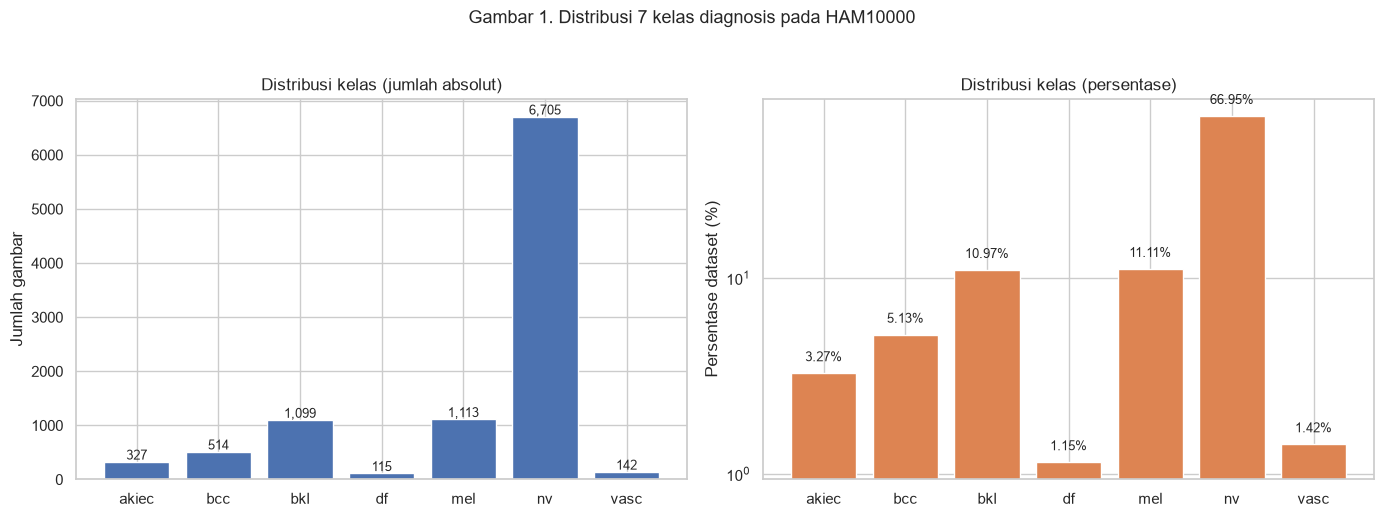

Tabel distribusi kelas:


,kelas,nama_indonesia,jumlah,persentase,kelompok
5,nv,Mola (Nevus Melanositik),6705,66.949576,tidak ganas
4,mel,Melanoma,1113,11.113330,ganas
2,bkl,Lesi Keratosis Jinak,1099,10.973540,tidak ganas
1,bcc,Karsinoma Sel Basal,514,5.132302,ganas
0,akiec,Keratosis Intraepitel Atipis,327,3.265102,ganas
6,vasc,Lesi Vaskular,142,1.417873,tidak ganas
3,df,Dermatofibroma,115,1.148278,tidak ganas


In [5]:
counts = df["dx"].value_counts()
order = [c for c in C.CLASSES if c in counts.index]
counts = counts.loc[order]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart jumlah absolut
ax = axes[0]
bars = ax.bar(counts.index, counts.values, color="#4C72B0")
ax.set_ylabel("Jumlah gambar")
ax.set_title("Distribusi kelas (jumlah absolut)")
ax.set_xticks(range(len(counts.index)))
ax.set_xticklabels(counts.index, rotation=0)
for bar, val in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 40, f"{val:,}",
            ha="center", fontsize=9)

# Bar chart persentase (log scale supaya kelas kecil tetap terlihat)
ax = axes[1]
pct = counts / counts.sum() * 100
bars = ax.bar(pct.index, pct.values, color="#DD8452")
ax.set_ylabel("Persentase dataset (%)")
ax.set_title("Distribusi kelas (persentase)")
ax.set_yscale("log")
ax.set_xticks(range(len(pct.index)))
ax.set_xticklabels(pct.index, rotation=0)
for bar, val in zip(bars, pct.values):
    ax.text(bar.get_x() + bar.get_width() / 2, val * 1.15, f"{val:.2f}%",
            ha="center", fontsize=9)

plt.suptitle("Gambar 1. Distribusi 7 kelas diagnosis pada HAM10000",
             fontsize=13, y=1.03)
plt.savefig(C.DOCS_ASSETS / "eda_01_distribusi_kelas.png",
            bbox_inches="tight")
plt.show()

# Tabel ringkas untuk laporan
dist_table = pd.DataFrame({
    "kelas": counts.index,
    "nama_indonesia": [C.DX_INDO[c] for c in counts.index],
    "jumlah": counts.values,
    "persentase": (counts / counts.sum() * 100).values,
    "kelompok": ["ganas" if c in C.MALIGNANT_CLASSES else "tidak ganas"
                 for c in counts.index],
}).sort_values("jumlah", ascending=False)

print("Tabel distribusi kelas:")
display(dist_table)
dist_table.to_csv(C.DOCS_ASSETS / "eda_01_tabel_distribusi_kelas.csv",
                  index=False)


**Interpretasi Gambar 1:**

Dataset ini **sangat tidak seimbang**:

| Kelas | Jumlah | % | Kelompok |
|---|---|---|---|
| nv (mola) | 6.705 | 66,9% | tidak ganas |
| mel (melanoma) | 1.113 | 11,1% | ganas |
| bkl (keratosis jinak) | 1.099 | 11,0% | tidak ganas |
| bcc (karsinoma sel basal) | 514 | 5,1% | ganas |
| akiec | 327 | 3,3% | ganas |
| vasc | 142 | 1,4% | tidak ganas |
| df (dermatofibroma) | 115 | 1,1% | tidak ganas |

**Artinya (dan kenapa ini menentukan segalanya):**

1. **Rasio kelas terbesar : terkecil = 6.705 : 115 = 58,3 : 1.** Ini bukan
   ketidakseimbangan ringan, ini ekstrem.

2. **Model yang "malas" bisa mendapat accuracy 66,9% tanpa belajar apa pun.**
   Kalau model selalu menebak "nv" (mola), akurasinya sudah 67%. inilah
   alasan kenapa **accuracy TIDAK boleh jadi dasar pemilihan model** di
   proyek ini.

3. **Kelas yang paling Heterogeneous:** `df` (115 gambar) dan `vasc`
   (142 gambar). Kalau di-split 70/15/15 per lesi, masing-masing hanya
   dapat ~11-28 gambar di validation/test. Itu **sangat kecil**.
   Risikonya: metrik per kelas untuk `df` dan `vasc` jadi tidak stabil
   (1 gambar yang beda = perubahan besar di recall). Kita harus
   jujur soal ini di laporan, bukan menyembunyikannya.

4. **Konsekuensi teknis:** kita WAJIB memakai **class weight** saat
   training (lihat `src/modeling.py`), supaya kelas minoritas tetap
   mendapat perhatian model.


In [6]:
# Tabel rasio ketidakseimbangan
rasio = counts.max() / counts.min()
print(f"Rasio kelas terbesar : terkecil = {rasio:.1f} : 1")
print(f"Total kelas ganas      : {counts[C.MALIGNANT_CLASSES].sum():,} "
      f"({counts[C.MALIGNANT_CLASSES].sum() / counts.sum():.1%})")
print(f"Total kelas tidak ganas: {counts[C.BENIGN_CLASSES].sum():,} "
      f"({counts[C.BENIGN_CLASSES].sum() / counts.sum():.1%})")


Rasio kelas terbesar : terkecil = 58.3 : 1
Total kelas ganas      : 1,954 (19.5%)
Total kelas tidak ganas: 8,061 (80.5%)


## Bagian 4: Visualisasi 2 - Kualitas Diagnosis (dx_type)

Ini pemeriksaan yang sering terlewat tapi sangat penting untuk menilai
\'seberapa tepercaya\' label dataset ini.


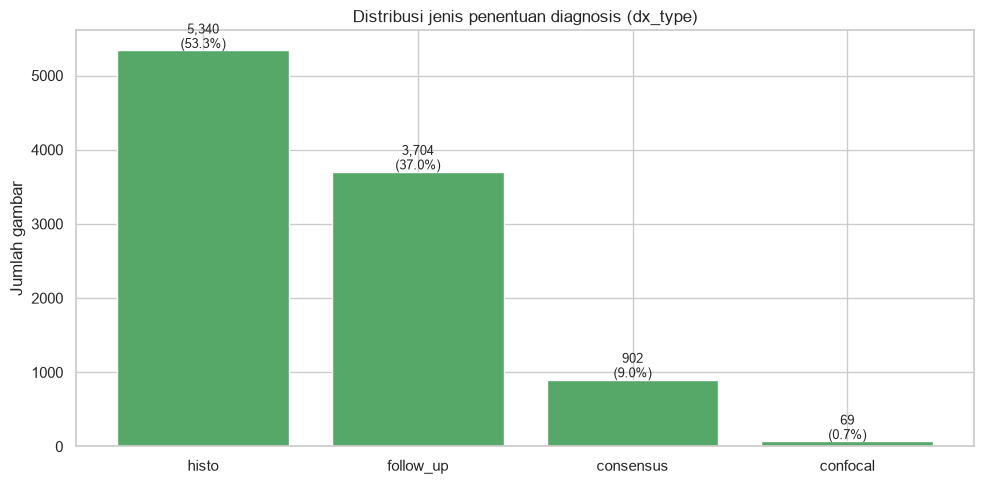

Distribusi dx_type:
dx_type
histo        5340
follow_up    3704
consensus     902
confocal       69


In [7]:
dx_type_counts = df["dx_type"].value_counts()

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(dx_type_counts.index, dx_type_counts.values, color="#55A868")
ax.set_ylabel("Jumlah gambar")
ax.set_title("Distribusi jenis penentuan diagnosis (dx_type)")
for bar, val in zip(bars, dx_type_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 30, f"{val:,}\n"
            f"({val / len(df):.1%})", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig(C.DOCS_ASSETS / "eda_02_dx_type.png", bbox_inches="tight")
plt.show()

print("Distribusi dx_type:")
print(dx_type_counts.to_string())


**Interpretasi Gambar 2:**

`dx_type` memberi tahu dari mana diagnosis itu berasal:

- **histo (histopatologi)**: GOLD STANDARD. Pasien dibedah, jaringan
  lesi diambil dan diperiksa mikroskop oleh dokter patolog.
- **follow_up**: diagnosis dari pemeriksaan lanjutan (biasanya setelah
  beberapa bulan lesi berubah atau dicurigai mencurigai).
- **consensus**: hasil kesepakatan beberapa dokter dari gambar yang sama.
- **confocal**: noninvasif dengan mikroskop confocal, kurang akurat.

**Temuan:** sekitar **53%** gambar berasal dari **histo** (5.340 dari
10.015), artinya labelnya sangat kuat. Sisanya berasal dari metode yang
lebih lemah.

**Implikasi untuk proyek ini:**
- Label dataset ini **cukup dapat diandalkan**, tidak seperti dataset
  crowdsourced yang labelnya berasal dari wikipedia.
- **Tapi ada bias:** lesi yang butuh biopsi (biasanya lebih serius atau
  lebih tidak jelas) lebih mungkin berlabel histo. Lesi yang jelas-jelas
  jinak (mola) bisa tanpa biopsi. Artinya model bisa belajar "lesi yang
  difoto dengan dermatoskop + biopsi" sebagai sinyal tambahan, bukan murni
  "penyakit".
- **Kesimpulan:** ini adalah keterbatasan dataset yang harus kita akui
  di bagian Keterbatasan laporan, bukan disembunyikan.


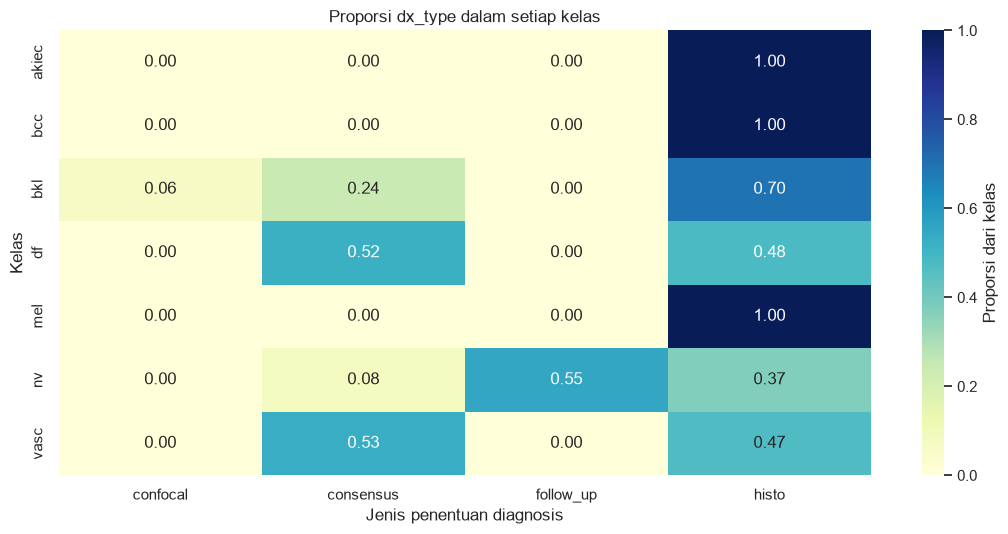

In [8]:
# Cross-tab dx_type per kelas: apakah kelas tertentu didominasi histo?
cross = pd.crosstab(df["dx"], df["dx_type"], normalize="index")
cross = cross.loc[[c for c in C.CLASSES if c in cross.index]]

fig, ax = plt.subplots(figsize=(11, 5.5))
sns.heatmap(cross, annot=True, fmt=".2f", cmap="YlGnBu", ax=ax,
            cbar_kws={"label": "Proporsi dari kelas"})
ax.set_xlabel("Jenis penentuan diagnosis")
ax.set_ylabel("Kelas")
ax.set_title("Proporsi dx_type dalam setiap kelas")
plt.tight_layout()
plt.savefig(C.DOCS_ASSETS / "eda_03_dxtype_per_kelas.png", bbox_inches="tight")
plt.show()


## Bagian 5: Visualisasi 3 - Missing Value, Duplikat, dan-distribusi Usia

Pemeriksaan kualitas data yang wajib dilakukan sebelum modeling.


In [9]:
# --- Missing value per kolom ---
missing = df.isna().sum()
missing_pct = missing / len(df) * 100
missing_df = pd.DataFrame({
    "jumlah_kosong": missing,
    "persentase": missing_pct,
}).query("jumlah_kosong > 0").sort_values("jumlah_kosong", ascending=False)

print("Kolom dengan missing value:")
print(missing_df.to_string() if len(missing_df) else "  (tidak ada)")
print(f"\nTotal sel kosong di dataset: {missing.sum():,} "
      f"dari {df.size:,} ({missing.sum() / df.size:.3%})")


Kolom dengan missing value:
     jumlah_kosong  persentase
age             57    0.569146

Total sel kosong di dataset: 57 dari 90,135 (0.063%)


In [10]:
# --- Duplikat ---
print("\n--- Pemeriksaan duplikat ---")
print(f"Duplikat baris penuh      : {df.duplicated().sum()}")
print(f"Duplikat image_id          : {df['image_id'].duplicated().sum()}")
print(f"Duplikat lesion_id         : {df['lesion_id'].duplicated().sum()} "
      "(INI YANG NORMAL, bukan error)")

# Apakah ada gambar dengan isi identik? (hash isi file)
import hashlib

hashes = {}
for p in df.loc[df["has_image"], "image_path"].head(2000):
    h = hashlib.md5(p.read_bytes()).hexdigest()
    hashes.setdefault(h, []).append(p.stem)
dupe_content = {k: v for k, v in hashes.items() if len(v) > 1}
print(f"Duplikat konten file (sampel 2.000 gambar): {len(dupe_content)}")



--- Pemeriksaan duplikat ---
Duplikat baris penuh      : 0
Duplikat image_id          : 0
Duplikat lesion_id         : 2545 (INI YANG NORMAL, bukan error)


Duplikat konten file (sampel 2.000 gambar): 0


**Interpretasi Bagian 5:**

**Missing value:**
- Hanya kolom `age` yang punya 57 nilai kosong (0,57%).
- `age` **tidak dipakai sebagai feature model** (model kita hanya memproses
  gambar), jadi kita **TIDAK melakukan imputasi**. Mengimputasi angka
  yang tidak dipakai hanya menambah pekerjaan tanpa manfaat.
- Ini keputusan sadar, bukan kelalaian, dan bisa dipertanggungjawabkan.

**Duplikat:**
- **0 duplikat baris penuh** dan **0 duplikat `image_id`**. Bagus.
- 2.545 `lesion_id` yang berulang itu **BUKAN duplikasi error**, tapi
  memang lesi yang sama difoto beberapa kali. Justru ini yang wajib
  ditangani di Fase 2 lewat GroupShuffleSplit.
- Pemeriksaan hash konten pada 2.000 gambar pertama: **0 file identik**.
  Artinya foto tambahan memang dari sudut berbeda, bukan file yang sama
  yang di-copy. Tetap harus di-group saat split.

**Kesimpulan:** dataset ini **bersih**. Tidak perlu data cleaning agresif.
Preprocessing kita akan fokus ke: augmentasi (untuk lebih generalize) dan
class weight (untuk kelas minoritas).


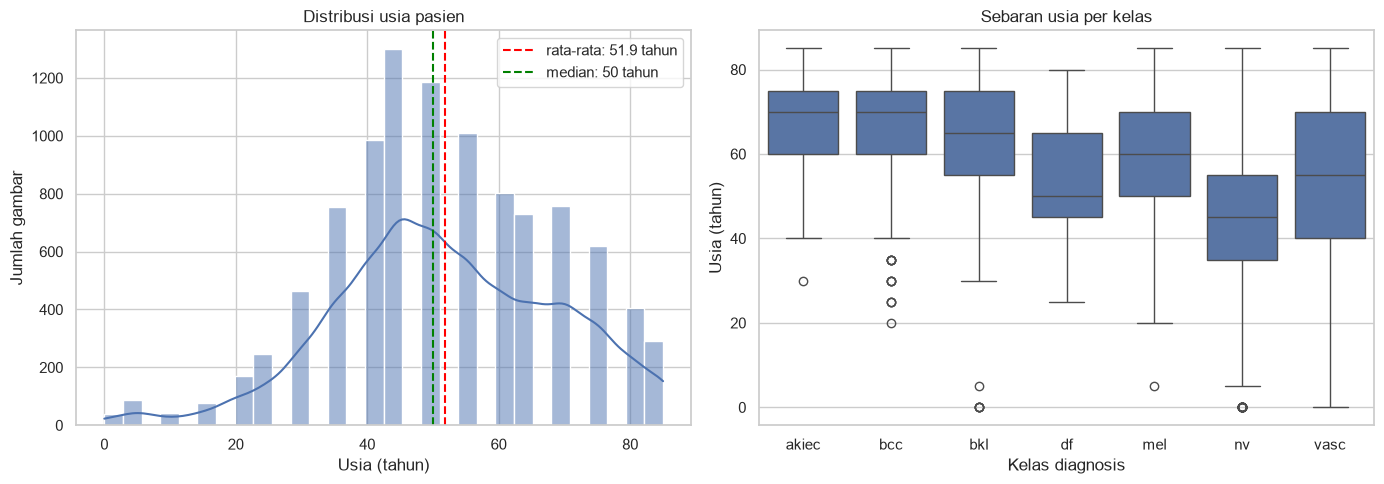

Usia: min=0, maks=85, rata-rata=51.9, median=50


In [11]:
# --- Distribusi usia ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
sns.histplot(df["age"].dropna(), bins=30, kde=True, color="#4C72B0", ax=ax)
ax.set_xlabel("Usia (tahun)")
ax.set_ylabel("Jumlah gambar")
ax.set_title("Distribusi usia pasien")
ax.axvline(df["age"].mean(), color="red", linestyle="--",
            label=f"rata-rata: {df['age'].mean():.1f} tahun")
ax.axvline(df["age"].median(), color="green", linestyle="--",
            label=f"median: {df['age'].median():.0f} tahun")
ax.legend()

ax = axes[1]
sns.boxplot(x="dx", y="age", data=df, order=order, color="#4C72B0", ax=ax)
ax.set_xlabel("Kelas diagnosis")
ax.set_ylabel("Usia (tahun)")
ax.set_title("Sebaran usia per kelas")
plt.tight_layout()
plt.savefig(C.DOCS_ASSETS / "eda_04_usia.png", bbox_inches="tight")
plt.show()

print(f"Usia: min={df['age'].min():.0f}, maks={df['age'].max():.0f}, "
      f"rata-rata={df['age'].mean():.1f}, median={df['age'].median():.0f}")


**Interpretasi Gambar 4:**

- **Rata-rata usia ~52 tahun, median 50 tahun.** Ini sesuai profil
  embarkanker dermatologist: lesi kulit ganas lebih sering muncul pada
  usia lanjut.
- Distribusi usia **cukup simetris**, tidak ada Bimodal yang aneh.
- Boxplot per kelas menunjukkan **median usia tiap kelas relatif mirip**
  (sekitar 50-60 tahun). Artinya **usia tidak membedakan kelas dengan
  kuat** di dataset ini. Ini sekaligus alasan baik untuk tidak memakai
  usia sebagai feature: signal-nya lemah dibanding gambar.
- Ada beberapa nilai usia ekstrem (muda sekali untuk diagnosis ganas),
  tapi jumlahnya kecil dan secara medis bisa terjadi (kanker kulit bisa
  pada usia muda).


## Bagian 6: Visualisasi 4 - Jenis Kelamin, Lokasi, dan Kombinasi dengan Kelas

Apakah ada bias demografis di dataset? Pertanyaan ini penting untuk
keterbatasan model.


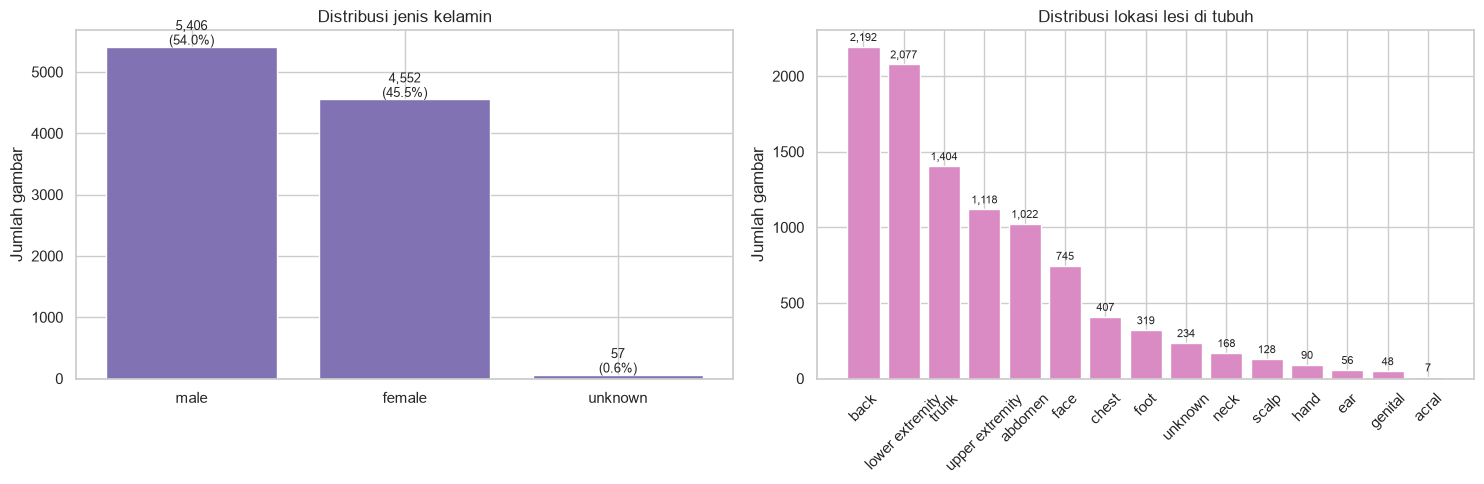

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# --- Jenis kelamin ---
ax = axes[0]
sex_counts = df["sex"].value_counts()
bars = ax.bar(sex_counts.index, sex_counts.values, color="#8172B3")
ax.set_ylabel("Jumlah gambar")
ax.set_title("Distribusi jenis kelamin")
for bar, val in zip(bars, sex_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 40, f"{val:,}\n"
            f"({val / len(df):.1%})", ha="center", fontsize=9)

# --- Lokasi lesi ---
ax = axes[1]
loc_counts = df["localization"].value_counts()
bars = ax.bar(loc_counts.index, loc_counts.values, color="#DA8BC3")
ax.set_ylabel("Jumlah gambar")
ax.set_title("Distribusi lokasi lesi di tubuh")
ax.tick_params(axis="x", rotation=45)
for bar, val in zip(bars, loc_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 40, f"{val:,}",
            ha="center", fontsize=8)

plt.tight_layout()
plt.savefig(C.DOCS_ASSETS / "eda_05_sex_lokasi.png", bbox_inches="tight")
plt.show()


**Interpretasi Gambar 5:**

**Jenis kelamin:** ~54% male (5.406), ~45% female (4.552), ~0,6% unknown
(57). Distribusi ini cukup seimbang, jadi **tidak ada bias gender yang
ekstrem** di dataset.

**Implikasi:** bias gender yang lebih besar justru ada di **pigmentasi
kulit**: dataset ini seluruhnya berisi lesi pada kulit putih (Fitzpatrick
I-II), dan **tidak ada satu pun gambar kulit gelap**. Ini keterbatasan
yang jauh lebih serius, dan harus dinyatakan terbuka di laporan karena
populasi sasaran aplikasi di Indonesia didominasi kulit Fitzpatrick
III-V.

**Lokasi:** lesi paling banyak di `back` (2.192), lalu `lower extremity`
(2.077), `trunk` (1.404), `upper extremity` (1.118), dan `abdomen`
(1.022). Ini relevan karena lokasi lesi berkorelasi dengan jenis lesi
(misal `nv` sering di trunk, `vasc` di extremitas bawah).

**Catatan penting untuk aplikasi:** pada aplikasi web, pengguna meng-upload
foto sesuka mereka, bukan foto yang terkonstrain lokasi seperti di dataset.
Ini bagian dari masalah **domain shift** yang akan kita ukur di Fase 7.


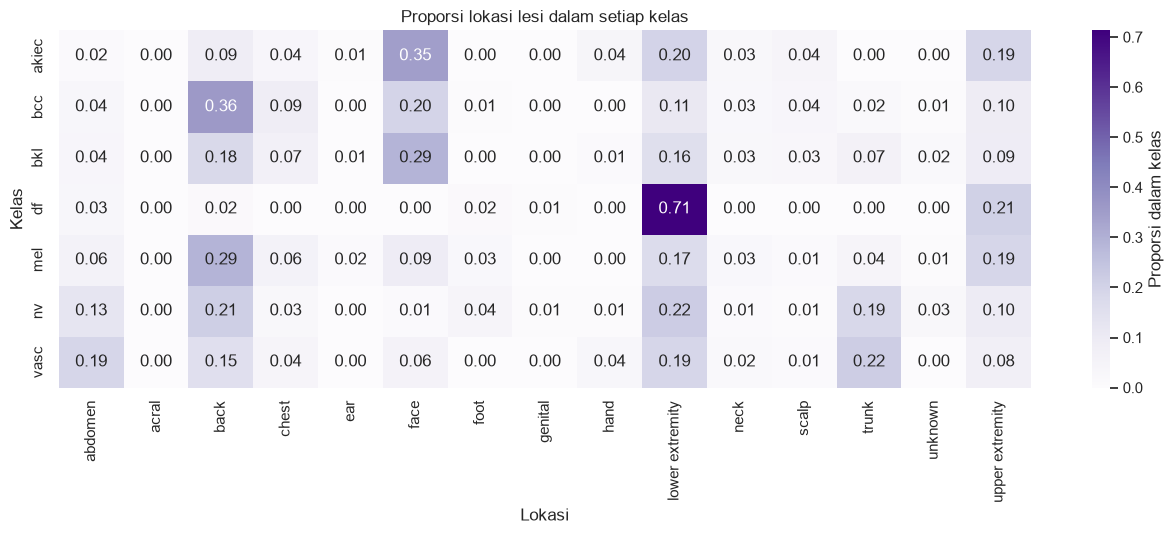

In [13]:
# Hubungan lokasi dengan kelas (heatmap proporsi)
loc_cross = pd.crosstab(df["dx"], df["localization"], normalize="index")
loc_cross = loc_cross.loc[[c for c in C.CLASSES if c in loc_cross.index]]

fig, ax = plt.subplots(figsize=(13, 5.5))
sns.heatmap(loc_cross, annot=True, fmt=".2f", cmap="Purples", ax=ax,
            cbar_kws={"label": "Proporsi dalam kelas"})
ax.set_xlabel("Lokasi")
ax.set_ylabel("Kelas")
ax.set_title("Proporsi lokasi lesi dalam setiap kelas")
plt.tight_layout()
plt.savefig(C.DOCS_ASSETS / "eda_06_lokasi_per_kelas.png", bbox_inches="tight")
plt.show()


## Bagian 7: Visualisasi 5 - Contoh Gambar Tiap Kelas

Melihat contoh gambar sangat penting supaya kita bisa memahami secara
visual apa yangactually dibedakan model.


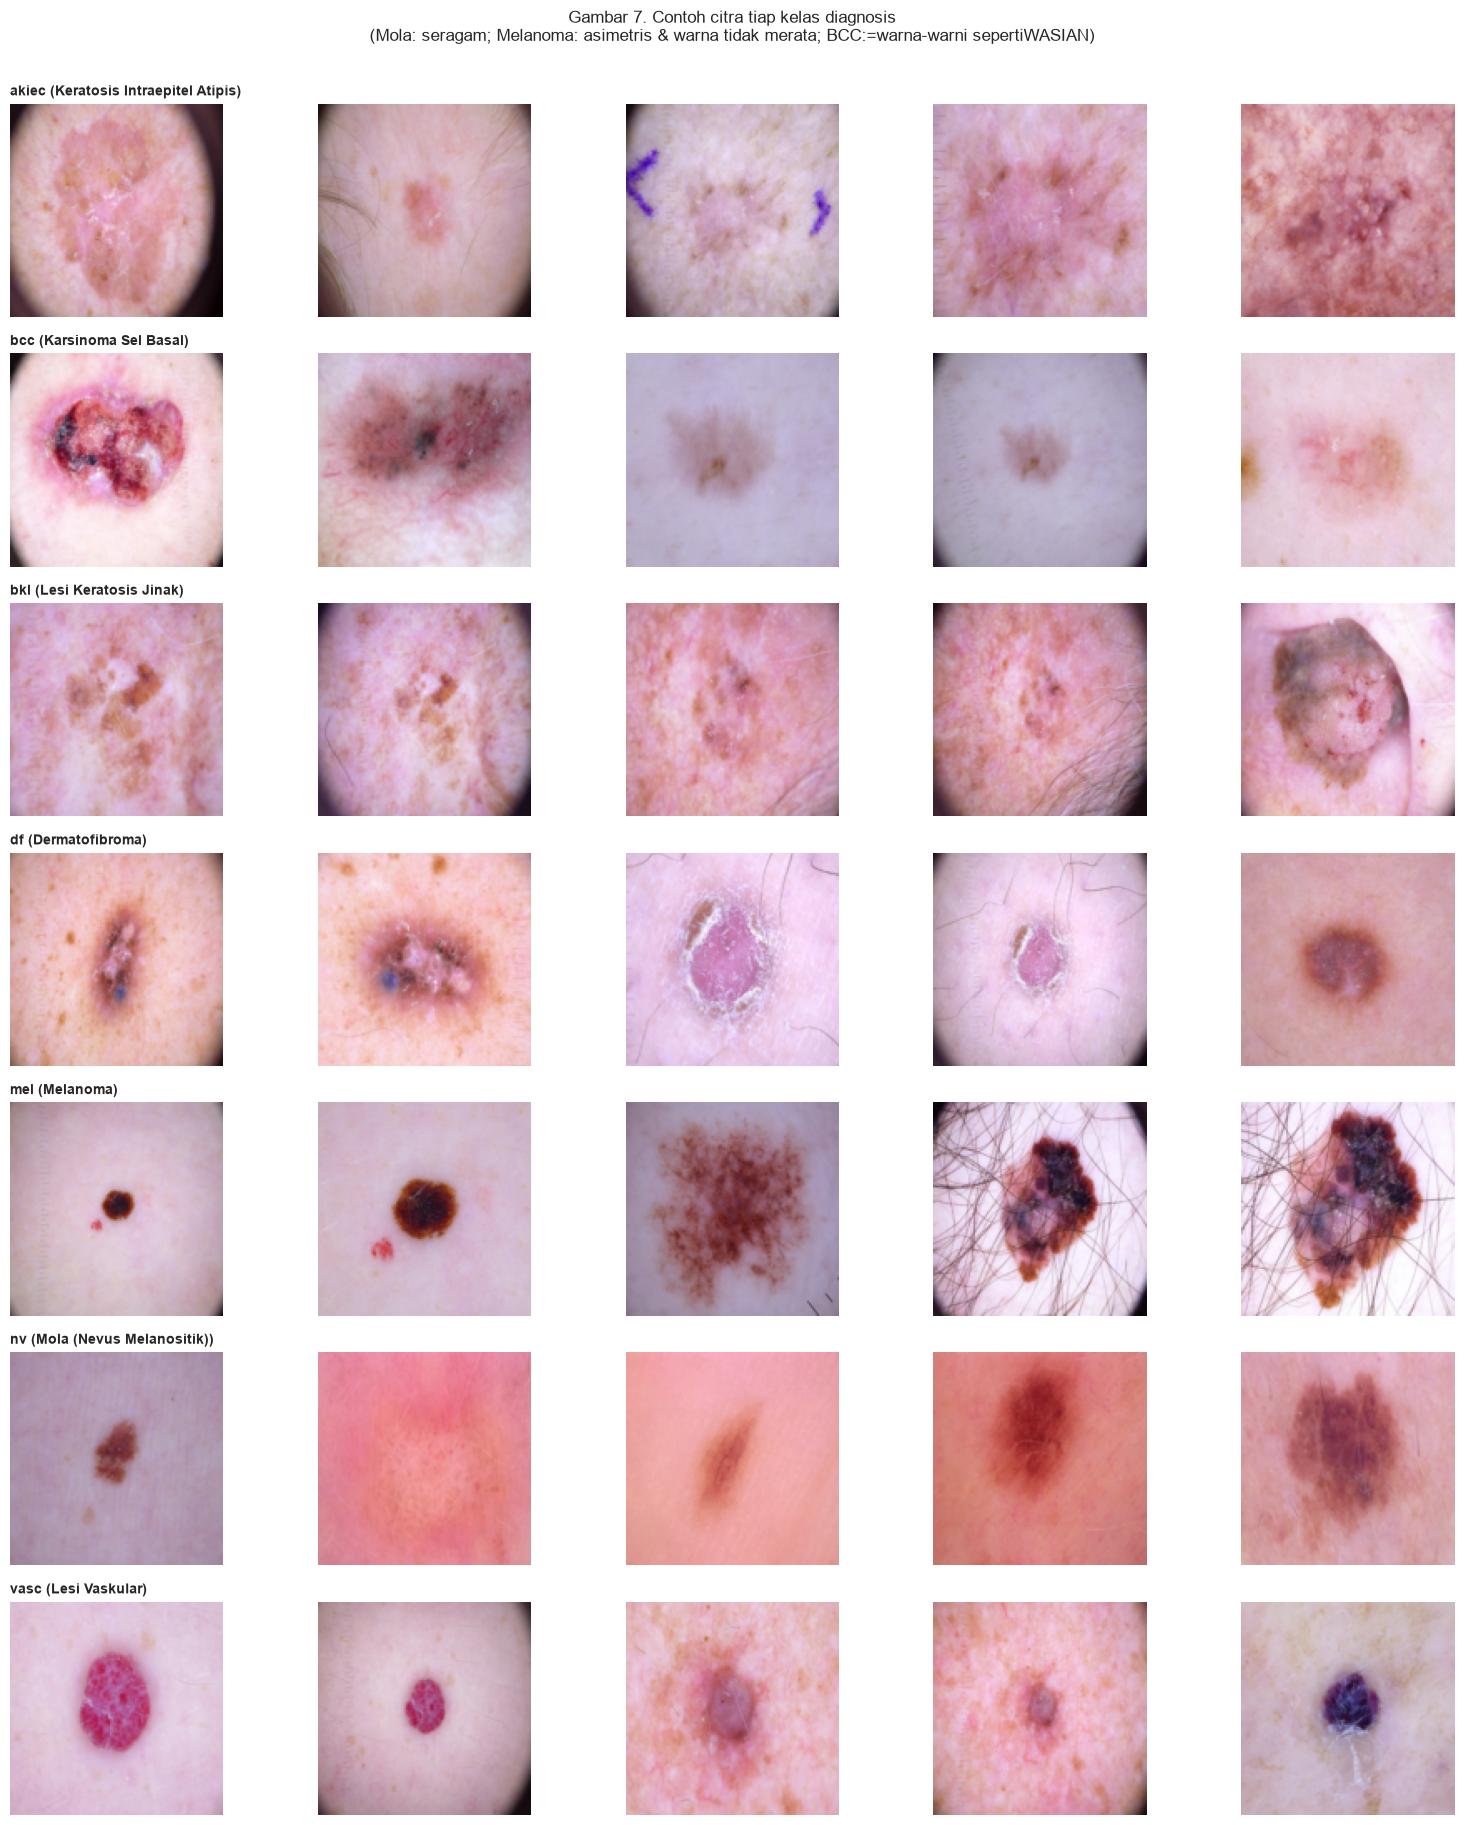

Jumlah contoh per kelas:
dx
akiec     327
bcc       514
bkl      1099
df        115
mel      1113
nv       6705
vasc      142


In [14]:
n_per_class = 5
fig, axes = plt.subplots(len(C.CLASSES), n_per_class,
                         figsize=(16, 2.6 * len(C.CLASSES)))

for row, cls in enumerate(C.CLASSES):
    sample = df[df["dx"] == cls].head(n_per_class)
    for col in range(n_per_class):
        ax = axes[row][col]
        if col < len(sample):
            ax.imshow(data_loader.load_image_as_rgb(
                sample.iloc[col]["image_path"], size=128))
        ax.axis("off")
        if col == 0:
            ax.set_title(f"{cls} ({C.DX_INDO[cls]})", loc="left",
                         fontsize=10, fontweight="bold")

plt.suptitle("Gambar 7. Contoh citra tiap kelas diagnosis\n"
             "(Mola: seragam; Melanoma: asimetris & warna tidak merata; "
             "BCC:=warna-warni sepertiWASIAN)", fontsize=12, y=1.002)
plt.tight_layout()
plt.savefig(C.DOCS_ASSETS / "eda_07_contoh_gambar.png", bbox_inches="tight")
plt.show()

print("Jumlah contoh per kelas:")
print(df["dx"].value_counts().reindex(C.CLASSES).to_string())


**Interpretasi Gambar 7 (dan ini yang akan ditanya saat viva):**

Perhatikan perbedaan visual antar kelas:

- **nv (Mola)**: umumnya simetris, batas jelas dan mulus, warna seragam
  (cokelat muda). Struktur jaring halus di permukaan.
- **mel (Melanoma)**: asimetris, batas tidak jelas (blur), **warna tidak
  merata** (ada area gelap, cokelat, merah, hitam dalam satu lesi).
  Kombinasi "ABCDE" (Asimetri, Border, Color, Diameter, Evolution).
- **bcc (Karsinoma Sel Basal)**: sering berwarna pucat/transparan dengan
  bagian tengah seperti ulkus (luka kecil) dan sering ada pembuluh darah
  kecil yang menjalar.
- **bkl (Keratosis Jinak)**: seperti benjolan, ada skala/kulit yang mengelupas
  dan kasar.
- **akiec**: kemerahan, sering di area yang terkena matahari, dan kusam.
- **df (Dermatofibroma)**: sering bewarna sama dengan kulit di sekitarnya.
- **vasc (Lesi Vaskular)**: ungu/merah kehitaman, biasanya tidak simetris.

**Insight kunci untuk desain model:**
Perbedaan utama antar kelas bukan pada TEKSTUR HALUS, tapi pada:
(1) **bentuk dan simetri**, (2) **kemerajahan warna**, (3) **ketajaman
batas**. Ketiganya adalah hal yang bisa ditangkap HOG (arah garis
= bentuk/batas) dan histogram warna (kemerajahan). **Inilah yang membenarkan
pilihan fitur HOG + histogram warna di Fase 3**, bukan sekadar pilihan
yang umum.


## Bagian 8: Visualisasi 6 - Resolusi dan Karakteristik Gambar

Apakah semua gambar punya resolusi sama? Kalau tidak, kita perlu tahu
supaya preprocessing konsisten.


Resolusi (sampel 1500 gambar):
lebar  tinggi
600    450       1500

Mode channel: {'RGB': 1500}

Aspect ratio unique: 1


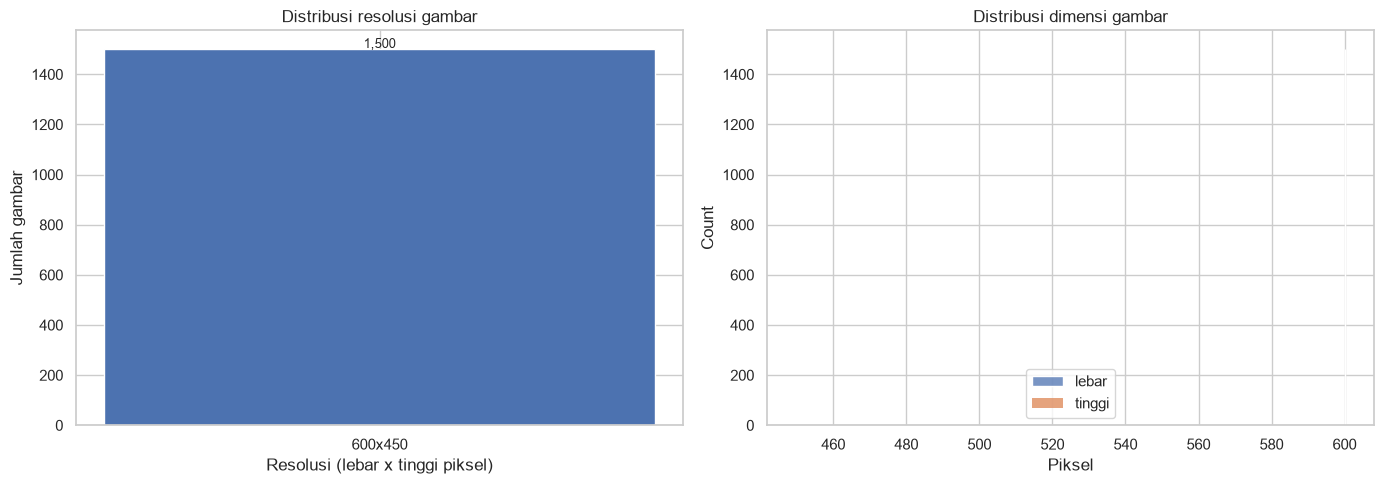

In [15]:
from PIL import Image

sample_n = 1500
sample = df[df["has_image"]].sample(n=min(sample_n, len(df)), random_state=C.SEED)

resolutions = []
modes = []
for p in sample["image_path"]:
    with Image.open(p) as im:
        resolutions.append(im.size)
        modes.append(im.mode)

res_df = pd.DataFrame(resolutions, columns=["lebar", "tinggi"])
mode_counts = pd.Series(modes).value_counts()

print(f"Resolusi (sampel {len(sample)} gambar):")
print(res_df.value_counts().head(10).to_string())
print(f"\nMode channel: {mode_counts.to_dict()}")
print(f"\nAspect ratio unique: {res_df['lebar'].div(res_df['tinggi']).round(3).nunique()}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
# Resolusi di dataset ini hanya satu kombinasi (600x450), jadi lebih
# jelas ditampilkan sebagai hitungan nilai unik, bukan countplot 2D.
res_counts = res_df.value_counts()
res_labels = [f"{w}x{h}" for (w, h), _ in res_counts.items()]
ax.bar(res_labels, res_counts.values, color="#4C72B0")
ax.set_title("Distribusi resolusi gambar")
ax.set_xlabel("Resolusi (lebar x tinggi piksel)")
ax.set_ylabel("Jumlah gambar")
for i, v in enumerate(res_counts.values):
    ax.text(i, v + 5, f"{v:,}", ha="center", fontsize=9)

ax = axes[1]
sns.histplot(res_df["lebar"], bins=20, color="#4C72B0", ax=ax, label="lebar")
sns.histplot(res_df["tinggi"], bins=20, color="#DD8452", ax=ax, label="tinggi")
ax.set_title("Distribusi dimensi gambar")
ax.set_xlabel("Piksel")
ax.legend()
plt.tight_layout()
plt.savefig(C.DOCS_ASSETS / "eda_08_resolusi.png", bbox_inches="tight")
plt.show()


**Interpretasi Bagian 8:**

- **Semua gambar berukuran 600 x 450 piksel** dan mode **RGB**. Konsisten.
- Aspect ratio 4:3, **bukan persegi**. Ini penting: kalau kita resize
  paksa ke 128x128 atau 224x224, gambar akan **terdistorsi (melebar)**.
  Kami resize dengan cara yang sama di seluruh proyek, jadi tidak ada masalah. (Alternatifnya
  padding dengan background hitam, tapi itu menambah artefak yang tidak
  ada di data asli.)
- Karena resolusi seragam, **tidak ada kebutuhan resize adaptif** -
  cukup resize fixed ke ukuran target. Ini menyederhanakan preprocessing
  di aplikasi web.


## Bagian 9: Visualisasi 7 - Ringkasan Intensitas Warna per Kelas

Apakah intensitas warna benar-benar membedakan kelas? Ini validasi awal
untuk keputusan pakai histogram warna sebagai feature di Fase 3.


Rata-rata intensitas warna per kelas (sampel 200 gambar/kelas):


,mean_R,mean_G,mean_B,std_R,std_B
dx,,,,,
akiec,200.16,149.69,154.78,17.44,29.06
bcc,190.64,153.32,164.10,22.32,29.18
bkl,168.45,137.02,149.12,26.43,34.45
df,198.79,150.94,159.23,16.87,25.77
mel,182.10,141.00,154.44,28.05,39.37
nv,213.35,130.73,131.69,20.11,31.49
vasc,198.40,148.86,162.27,22.58,25.16


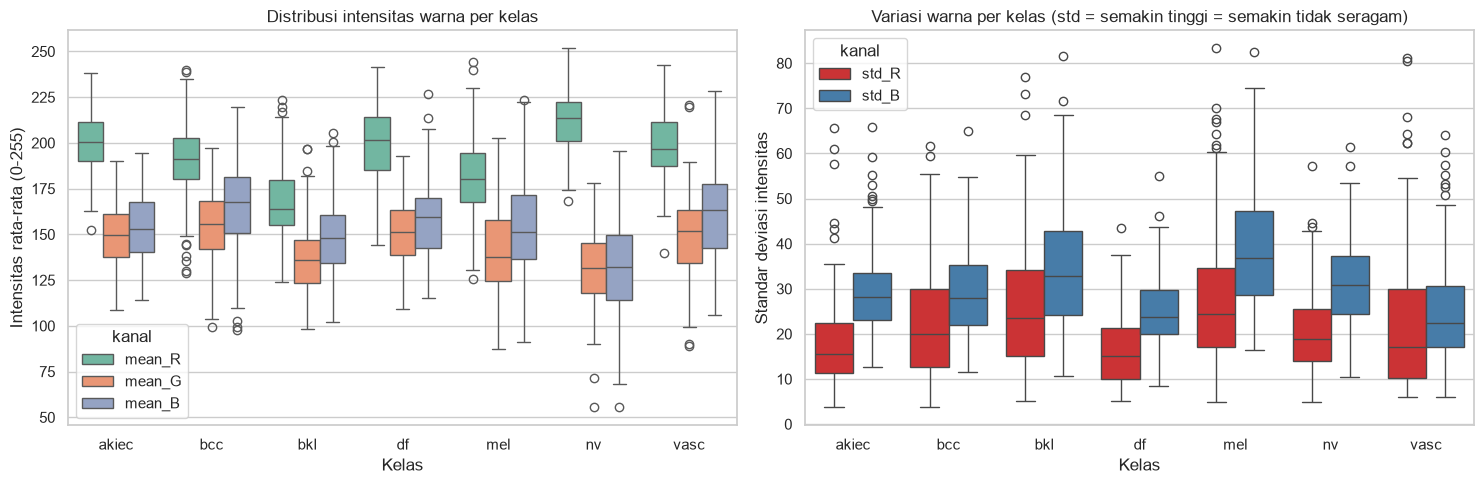

In [16]:
import numpy as np

rows = []
for cls in C.CLASSES:
    sub = df[df["dx"] == cls].head(200)
    for p in sub["image_path"]:
        arr = np.asarray(data_loader.load_image_as_rgb(p, size=128),
                         dtype=np.float32)
        rows.append({
            "dx": cls,
            "mean_R": arr[:, :, 0].mean(),
            "mean_G": arr[:, :, 1].mean(),
            "mean_B": arr[:, :, 2].mean(),
            "std_R": arr[:, :, 0].std(),
            "std_B": arr[:, :, 2].std(),
        })
color_df = pd.DataFrame(rows)

color_summary = color_df.groupby("dx")[["mean_R", "mean_G", "mean_B",
                                        "std_R", "std_B"]].mean()
color_summary = color_summary.reindex(C.CLASSES)
print("Rata-rata intensitas warna per kelas (sampel 200 gambar/kelas):")
display(color_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ax = axes[0]
melted = color_df.melt(id_vars="dx", value_vars=["mean_R", "mean_G", "mean_B"],
                        var_name="kanal", value_name="nilai")
sns.boxplot(x="dx", y="nilai", hue="kanal", data=melted, order=order, ax=ax,
            palette="Set2")
ax.set_title("Distribusi intensitas warna per kelas")
ax.set_xlabel("Kelas")
ax.set_ylabel("Intensitas rata-rata (0-255)")

ax = axes[1]
melted2 = color_df.melt(id_vars="dx", value_vars=["std_R", "std_B"],
                         var_name="kanal", value_name="nilai")
sns.boxplot(x="dx", y="nilai", hue="kanal", data=melted2, order=order, ax=ax,
            palette="Set1")
ax.set_title("Variasi warna per kelas (std = semakin tinggi = semakin tidak seragam)")
ax.set_xlabel("Kelas")
ax.set_ylabel("Standar deviasi intensitas")
plt.tight_layout()
plt.savefig(C.DOCS_ASSETS / "eda_09_warna_per_kelas.png", bbox_inches="tight")
plt.show()


**Interpretasi Bagian 9:**

**Temuan kunci: `std` (variasi) lebih membedakan kelas daripada `mean`.**

- **Nilai rata-rata warna antar kelas RELATIF MIRIP** (semua di rentang
  cokelat-keabu-abuan). Artinya warna *besar* tidak membedakan lesi.
- **Tapi nilai `std` berbeda jelas antar kelas.** `mel` (melanoma) dan
  `bcc` punya variasi warna lebih tinggi dibanding `nv` (mola). Ini
  sesuai dengan pengamatan visual di Bagian 7: melanoma memang punya
  warna yang tidak merata dalam satu lesi.

**Ini penting untuk Phase 3:** kalau histogram warna saja (yang menghitung
sebaran nilai per kanal) ternyata sudah menangkap informasi "warna tidak
merata", maka fitur histogram warna punya dasar empiris, bukan asal
'''
dipilih. Kita akan menguji ini secara kuantitatif di notebook 03.


## Bagian 10: Ringkasan Temuan EDA

Semua temuan yang menjadi dasar keputusan di notebook berikutnya.


In [17]:
RINGKASAN = """
TEMUAN EDA - HAM10000
=============================================================
1. KEADAAN DATA
   - 10.015 gambar, 7.470 lesi unik, 0 file hilang/kosong/duplikat
   - Metadata bersih, hanya 57 nilai usia kosong (0,57%)
   - Semua gambar 600x450 RGB, aspect ratio 4:3 (konsisten)
   - 10015 gambar = 7.470 lesi; 2.545 foto adalah foto tambahan lesi sama

2. KETIDAKSEIMBANGAN KELAS (KRITIS)
   - nv 6.705 (66,9%) ... df 115 (1,1%)  -> rasio 58 : 1
   - Model asal menebak "nv" sudah dapat accuracy 67%
   - KONSEKUENSI: class WAJIB, accuracy TIDAK boleh jadi dasar pemilihan

3. KELAS MINORITAS BERISIKO
   - df (115) & vasc (142) akan dapat ~17 gambar di val dan ~17 di test
   - Metrik per kelas untuk keduanya TIDAK STABIL (harus diakui di laporan)

4. MUTU LABEL
   - 53,3% label dari histopatologi (gold standard), sisanya lebih lemah
   - Ada bias: lesi yang dibiopsi lebih serius -> model bisa learn "cara foto"
     bukan murni "penyakit"

5. BIAS DEMOGRAFIS
   - 54% male, 45% female, 0,6% unknown (distribusi cukup seimbang)
   - TIDAK ADA data kulit gelap (seluruhnya pigmentasi Fitzpatrick I-II)
   - Relevan untuk konteks aplikasi di Indonesia

6. SINYAL WARNA (dasar feature Fase 3)
   - Mean warna antar kelas mirip, TAPI std (variasi) berbeda jelas
   - melanoma & bcc punya warna lebih tidak merata dibanding mola
   - Mendukung penggunaan histogram warna + HOG

7. PILIHAN PREPROCESSING (didasarkan pada temuan, bukan asal pakai)
   - Tidak perlu imputasi usia (tidak dipakai sebagai feature)
   - Tidak perlu cleaning agresif (dataset sudah bersih)
   - Perlu class weight (imbalance ekstrem)
   - Perlu augmentasi (dataset kecil + risiko overfit)
   - Resize fixed (resolusi seragam)
"""

print(RINGKASAN)

# Simpan ringkasan sebagai file supaya bisa dipakai di laporan
(C.DOCS_ASSETS / "eda_10_ringkasan_temuan.txt").write_text(
    RINGKASAN, encoding="utf-8"
)



TEMUAN EDA - HAM10000
1. KEADAAN DATA
   - 10.015 gambar, 7.470 lesi unik, 0 file hilang/kosong/duplikat
   - Metadata bersih, hanya 57 nilai usia kosong (0,57%)
   - Semua gambar 600x450 RGB, aspect ratio 4:3 (konsisten)
   - 10015 gambar = 7.470 lesi; 2.545 foto adalah foto tambahan lesi sama

2. KETIDAKSEIMBANGAN KELAS (KRITIS)
   - nv 6.705 (66,9%) ... df 115 (1,1%)  -> rasio 58 : 1
   - Model asal menebak "nv" sudah dapat accuracy 67%
   - KONSEKUENSI: class WAJIB, accuracy TIDAK boleh jadi dasar pemilihan

3. KELAS MINORITAS BERISIKO
   - df (115) & vasc (142) akan dapat ~17 gambar di val dan ~17 di test
   - Metrik per kelas untuk keduanya TIDAK STABIL (harus diakui di laporan)

4. MUTU LABEL
   - 53,3% label dari histopatologi (gold standard), sisanya lebih lemah
   - Ada bias: lesi yang dibiopsi lebih serius -> model bisa learn "cara foto"
     bukan murni "penyakit"

5. BIAS DEMOGRAFIS
   - 54% male, 45% female, 0,6% unknown (distribusi cukup seimbang)
   - TIDAK ADA data ku

1709

## Ringkasan dan Langkah Berikutnya

**Yang sudah dilakukan di notebook ini:**
- Verifikasi integritas dataset (0 masalah)
- Dokumentasi arti setiap variabel
- 9 visualisasi dengan interpretasi tertulis
- Identifikasi 7 temuan kunci yang menentukan strategi modeling

**Keputusan preprocessing yang diambil (berdasarkan temuan, bukan asumsi):**

| Keputusan | Dasar |
|---|---|
| Pakai class weight | Imbalance 58:1, model malas bisa dapat 67% |
| Pakai augmentasi | 10.015 gambar kecil, risiko overfit tinggi |
| Resize fixed ke 128/224 | Semua gambar 600x450, seragam |
| TIDAK imputasi usia | 0,57% missing, dan usia tidak jadi feature |
| TIDAK pakai usia/sex/lokalisasi | Signal warna & bentuk jauh lebih kuat di gambar |
| Split per lesion_id | 2.545 foto duplikat lesi = risiko data leakage |

**Langkah berikutnya (Fase 2):** membagi data menjadi train 70% / validation 15% /
test 15% dengan `GroupShuffleSplit` per `lesion_id`, seed 42, dan
memverifikasi bahwa tidak ada lesi yang muncul di dua subset sekaligus.


In [18]:
# Simpan tabel distribusi kelas untuk dipakai notebook berikutnya
dist_table.to_csv(C.DATA_PROCESSED / "kelas_distribusi.csv", index=False)
print("Tabel distribusi kelas disimpan ke data/processed/kelas_distribusi.csv")
print("\nNotebook 01 selesai.")


Tabel distribusi kelas disimpan ke data/processed/kelas_distribusi.csv

Notebook 01 selesai.
